# Instructions

1. repliement spectral 
    - créer un sinus à $f_1=100Hz$, échantillonné à $f_s=48kHz$
    - calculer sa TF et la tracer
    - augmenter sa fréquence jusqu'à observer du repliement spectral
    - exprimer la position du pic replié en fonction de $f_1$ et $f_s$
    - créer un sinus à $f_1 > f_s/2$ qui à l'écoute sonne comme un sinus à $f_1=100Hz$

2. fft vs. rfft 
    - créer deux sinus à $f_1=5kHz$ et $f_2=10kHz$, le second déphasé de $\pi/2$
    - calculer et tracer sa fft à l'aide de la function `rfft` du module `numpy.fft`
    - idem avec la function `fft` du même module
    - modifier le résultat de la fonction `fft` pour correspondre à celui de la fonction `rfft`, expliquer

3. résolution fréquentielle
    - créer un signal $x$ de $n=3000$ samples, échantillonné à $f_s=48kHz$, composé de deux sinus: l'un à $f_1 = 1kHz$, l'autre à $f_2 = f_1 + \delta f$ (commencer avec $x = 100Hz$)
    - calculer et tracer la fft de x en zoomant sur les deux pics attendus
    - diminuer $\delta f$ jusqu'à ce que les deux pics n'en forment qu'un seul
    - relever les valeurs limites de résolution $n=[300, 500, 1000, 2000, 3000]$
    - tracer ces valeurs en fonction de $n$, y superposer la courbe $y = fs/n_samples$

4. manipulation de la phase
    - charger le fichier audio "drums.wav"
    - calculer sa fft, en extraire le module et la phase
    - appliquer de légères modification à la phase (e.g. multiplier par 0.9 ou -1)
    - revenir dans le domaine temporel, tracer et écouter le résultat

# Correction

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from IPython.display import Audio
import scipy

## 1. Repliement spectral

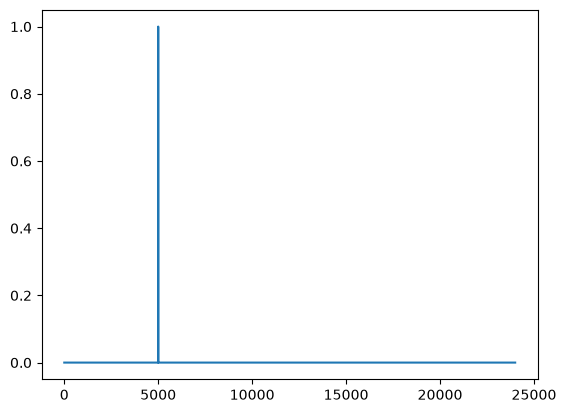

In [2]:
# init locals
fs = 48000

# create sine
duration_in_sec = 1
t = np.arange(duration_in_sec * fs) / fs
f1_alias = 5000
f1 = fs/2 + (fs/2 - f1_alias)
x = np.sin(2*math.pi*f1*t)

# fft
n = len(x)
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.abs(X))
plt.show()

## 2. rfft vs. fft

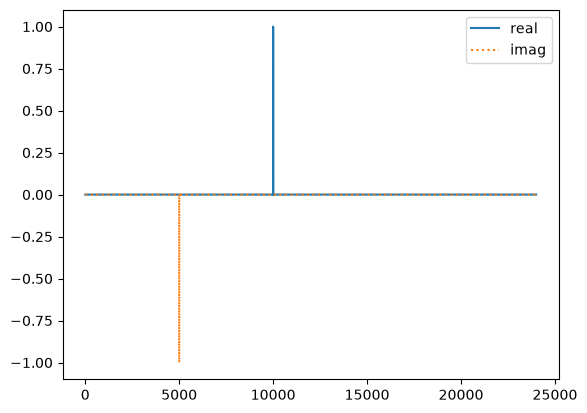

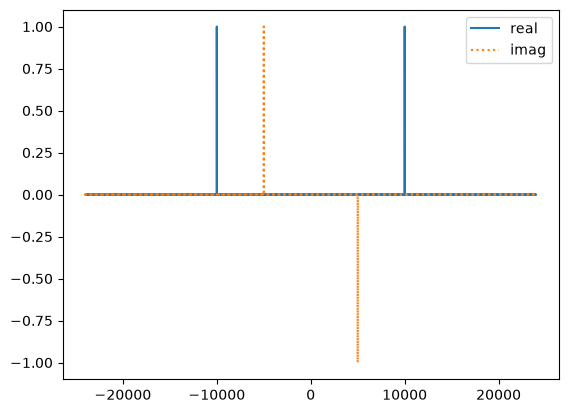

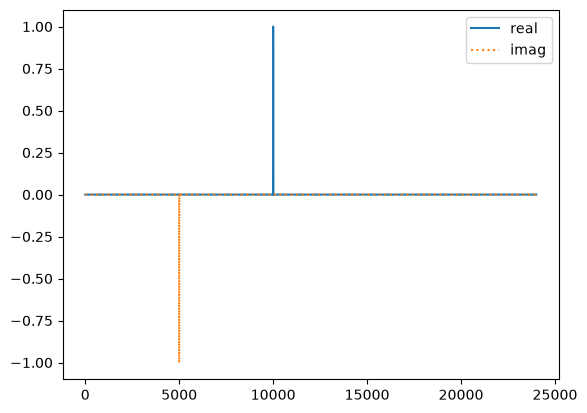

In [3]:
# init locals
fs = 48000

# create sine
duration_in_sec = 1
t = np.arange(duration_in_sec * fs) / fs
f1, f2 = 5000, 10000
x = np.sin(2*math.pi*f1*t) + np.sin(2*math.pi*f2*t + math.pi/2)

# rfft
n = len(x)
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.real(X), label='real')
plt.plot(f, np.imag(X), ':', label='imag')
plt.legend(); plt.show()

# fft
n = len(x)
X = np.fft.fft(x, n) / (n/2)
f = np.fft.fftfreq(n, 1/fs)

# plot
plt.plot(f, np.real(X), label='real')
plt.plot(f, np.imag(X), ':', label='imag')
plt.legend(); plt.show()

# fft -> rfft
n = len(X)//2
X = X[0:n]
f = f[0:n]

# plot
plt.plot(f, np.real(X), label='real')
plt.plot(f, np.imag(X), ':', label='imag')
plt.legend(); plt.show()

## 3. Résolution fréquentielle

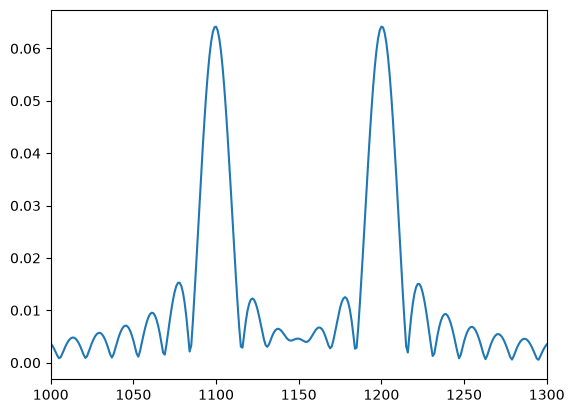

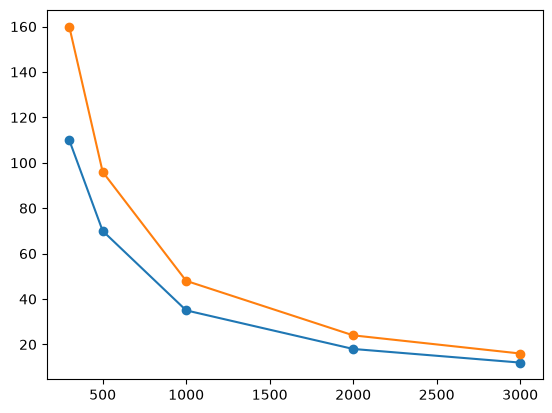

In [7]:
# init locals
fs = 48000

# create sine
num_samples = 3000
t = np.arange(num_samples) / fs
f1, f2 = 1100, 1200
x = np.sin(2*math.pi*f1*t) + np.sin(2*math.pi*f2*t)

# rfft
n = fs
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.abs(X))
o = 100; plt.xlim([f1-o, f2+o])
plt.show()

# plot
delta_f = np.array([110, 70, 35, 18, 12])
n_samples = np.array([300, 500, 1000, 2000, 3000])
plt.plot(n_samples, delta_f, 'o-', label = 'data points')
plt.plot(n_samples, fs/n_samples, 'o-', label = 'fs/n_samples')
plt.show()


## 4. Phase manipulation

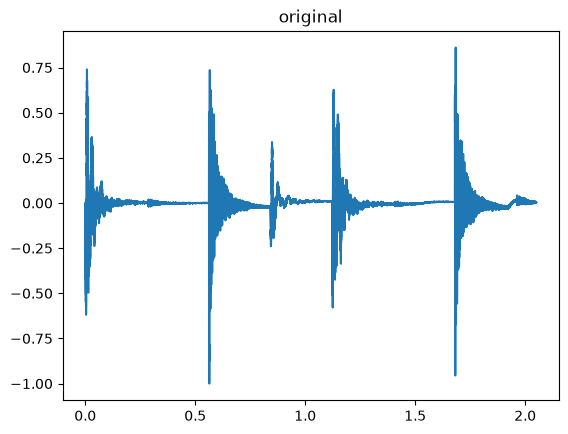

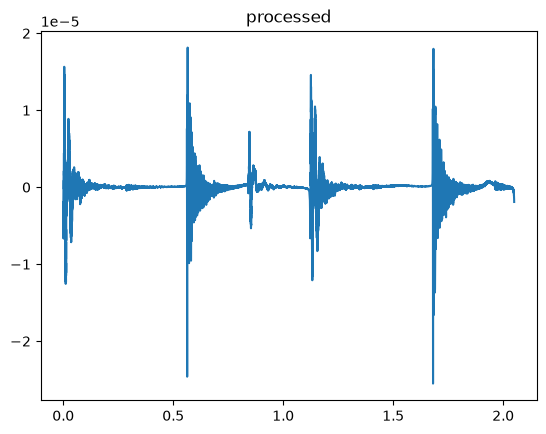

In [11]:
# load audio
fs, audio = scipy.io.wavfile.read('../assets/drums.wav')
audio = audio / np.max(np.abs(audio))

# play
display(Audio(audio, rate=fs))

# plot
t = np.arange(len(audio))/fs
plt.plot(t, audio)
plt.title('original')
plt.show()

# fft
n = len(audio)
X = np.fft.rfft(audio, n) / (n/2)

# scaled phase
phase = np.angle(X) + math.pi/2
X = np.abs(X) * np.exp(1j*phase)

# ifft
audio_out = np.fft.irfft(X, n)

# play
display(Audio(audio_out, rate=fs))

# plot
t = np.arange(len(audio_out))/fs
plt.plot(t, audio_out)
plt.title('processed')
plt.show()


# WIP

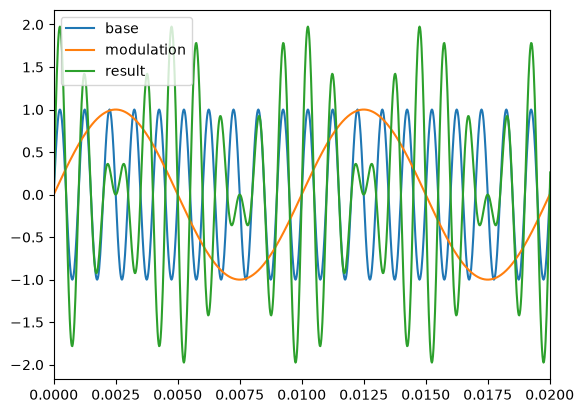

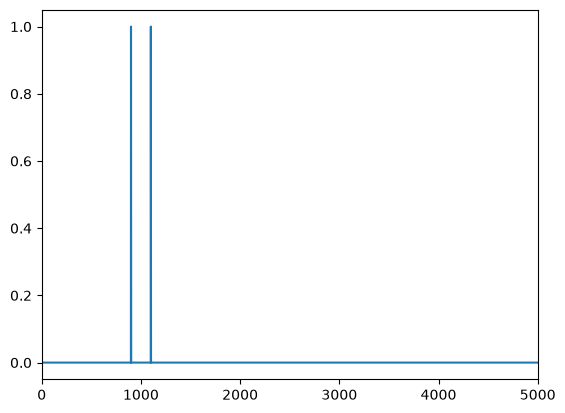

In [ ]:
# init locals
fs = 48000

# create sine
duration_in_sec = 1
t = np.arange(int(duration_in_sec*fs)) / fs
f1, f2 = 1000, 100
x1 = np.sin(2*math.pi*f1*t)
x2 = np.sin(2*math.pi*f2*t)
x = x1 * x2
# x = np.sin(2*math.pi*(f1-f2)*t) + np.sin(2*math.pi*(f1+f2)*t) 

# play
display(Audio(x, rate=fs))

# plot
plt.plot(t, x1, label='base')
plt.plot(t, x2, label='modulation')
plt.plot(t, x, label='result')
plt.xlim([0, 2/f2])
plt.legend()
plt.show()

# rfft
n = fs
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.abs(X))
plt.xlim([0, 5000])
plt.show()